# Churn Models

**Goal:** find the model that best ranks customers by churn risk.
**Input:** `features.parquet` from `04_features.ipynb`.

Models learn on the train rows only and are compared on the valid snapshot. The test snapshot is used once, at the end.

## Setup and load the features

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lightgbm import LGBMClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Folder where the charts are saved (they are used in the README)
fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Load the features (each row = one customer at one snapshot date, with the churn answer)
data = pd.read_parquet("../data/processed/features.parquet")

# Every column except these four is a feature
feature_cols = data.columns.drop(["customer_id", "cutoff", "split", "churn"])

# Split by time: train = older snapshots, valid = Jun 2011, test = Sep 2011
train = data[data["split"] == "train"]
valid = data[data["split"] == "valid"]
test = data[data["split"] == "test"]

X_train, y_train = train[feature_cols], train["churn"]
X_valid, y_valid = valid[feature_cols], valid["churn"]
X_test, y_test = test[feature_cols], test["churn"]

print("Features:", len(feature_cols))
print("Rows | train:", f"{len(train):,}", "| valid:", f"{len(valid):,}", "| test:", f"{len(test):,}")
print("Churn rate | train:", f"{y_train.mean():.1%}", "| valid:", f"{y_valid.mean():.1%}", "| test:", f"{y_test.mean():.1%}")

Features: 19
Rows | train: 30,885 | valid: 2,629 | test: 2,783
Churn rate | train: 52.0% | valid: 50.3% | test: 38.3%


## Model 1: logistic regression

In [2]:
# Steps in a row: fill empty values with the median, make skewed features less skewed and put them
# on the same scale, then fit the logistic regression
logit = make_pipeline(
    SimpleImputer(strategy="median"),
    PowerTransformer(),
    LogisticRegression(max_iter=1000),
)
logit.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('powertransformer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['recency_days','n_invoices','n_purchase_days',...,'n_return_lines', 'return_rate','is_uk']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of 

## Model 2: LightGBM (a tree model that finds complex patterns)

In [3]:
# LightGBM builds many small decision trees, each one correcting the mistakes of the previous ones.
# The settings are modest on purpose, to avoid memorizing the training data (overfitting).
lgbm = LGBMClassifier(
    n_estimators=300,        # number of small trees
    learning_rate=0.05,      # how much each new tree is allowed to correct
    num_leaves=15,           # keeps every tree small
    min_child_samples=50,    # a rule must be based on at least 50 customers
    subsample=0.8,           # each tree sees 80% of the rows
    subsample_freq=1,
    colsample_bytree=0.8,    # each tree sees 80% of the features
    random_state=42,         # same result every time
    verbose=-1,              # no log messages
)
lgbm.fit(X_train, y_train)

# Overfitting check: a model that memorizes scores much higher on the data it learned from
print("ROC-AUC on train:", round(roc_auc_score(y_train, lgbm.predict_proba(X_train)[:, 1]), 3))
print("ROC-AUC on valid:", round(roc_auc_score(y_valid, lgbm.predict_proba(X_valid)[:, 1]), 3))

ROC-AUC on train: 0.821
ROC-AUC on valid: 0.773


## Compare the models on the valid snapshot

In [4]:
# Risk score of every customer in the valid snapshot (higher = more likely to churn).
# The baseline is a simple rule: the longer a customer has been silent, the higher the risk.
scores = pd.DataFrame({
    "Recency rule": X_valid["recency_days"],
    "Logistic regression": logit.predict_proba(X_valid)[:, 1],
    "LightGBM": lgbm.predict_proba(X_valid)[:, 1],
})

results = {}
for model in scores:
    # The 10% of customers with the highest risk score, and how many of them really churned
    top10 = valid.assign(score=scores[model]).nlargest(int(len(valid) * 0.10), "score")
    results[model] = [
        roc_auc_score(y_valid, scores[model]),              # 0.5 = random guessing, 1.0 = perfect ranking
        average_precision_score(y_valid, scores[model]),    # random guessing would give the churn rate
        top10["churn"].mean(),                              # of the 10% flagged, how many really churn
    ]

results = pd.DataFrame(results, index=["roc_auc", "pr_auc", "top10_churn_rate"]).T
results["top10_lift"] = results["top10_churn_rate"] / y_valid.mean()    # how many times better than random guessing

print("Valid churn rate (random guessing):", round(y_valid.mean(), 3))
results.round(3)

Valid churn rate (random guessing): 0.503


,roc_auc,pr_auc,top10_churn_rate,top10_lift
Recency rule,0.653,0.632,0.698,1.389
Logistic regression,0.772,0.755,0.874,1.738
LightGBM,0.773,0.754,0.851,1.693


## Final check on the test snapshot (used once)

The two trained models perform the same, so we choose the simpler one: the logistic regression.

In [5]:
# The test snapshot was never used to choose or tune anything. We score it once.
score_test = logit.predict_proba(X_test)[:, 1]
test_scored = test.assign(score=score_test)

# Risk score of every customer in the test snapshot: the chosen model and the simple rule
scores_test = pd.DataFrame({
    "Logistic regression": score_test,
    "Recency rule": X_test["recency_days"],
})

test_results = {}
for model in scores_test:
    top10 = test.assign(score=scores_test[model]).nlargest(int(len(test) * 0.10), "score")
    test_results[model] = [
        roc_auc_score(y_test, scores_test[model]),
        average_precision_score(y_test, scores_test[model]),
        top10["churn"].mean(),
    ]

test_results = pd.DataFrame(test_results, index=["roc_auc", "pr_auc", "top10_churn_rate"]).T
test_results["top10_lift"] = test_results["top10_churn_rate"] / y_test.mean()
print(test_results.round(3))

# The churn rate changed with the season (train 52%, test 38%): are the predicted probabilities still right?
print("Average predicted churn probability:", round(score_test.mean(), 3), "| real churn rate:", round(y_test.mean(), 3))

                     roc_auc  pr_auc  top10_churn_rate  top10_lift
Logistic regression    0.764   0.635             0.712       1.861
Recency rule           0.656   0.528             0.601       1.570
Average predicted churn probability: 0.513 | real churn rate: 0.383


## Churn rate by risk decile

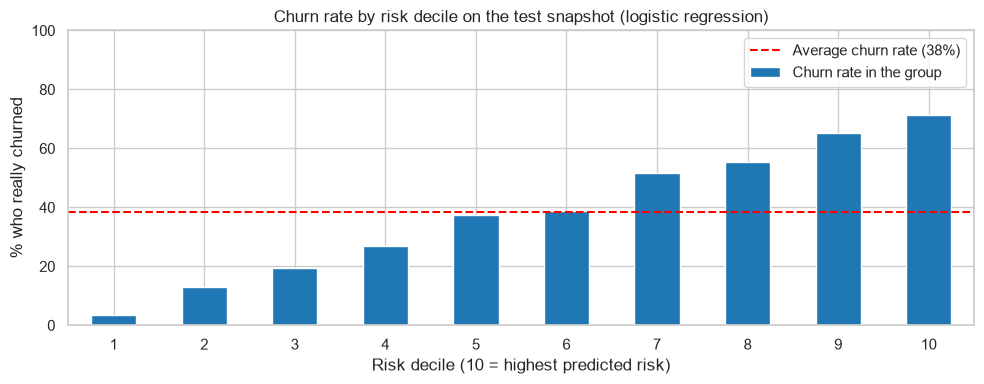

In [6]:
# Split the customers into 10 equal groups by risk (10 = highest risk) and see how many really churned in each
test_scored["decile"] = pd.qcut(test_scored["score"].rank(method="first"), 10, labels=False) + 1
by_decile = test_scored.groupby("decile")["churn"].mean() * 100

by_decile.plot.bar(color="tab:blue", label="Churn rate in the group", title="Churn rate by risk decile on the test snapshot (logistic regression)")
plt.axhline(y_test.mean() * 100, color="red", linestyle="--", label=f"Average churn rate ({y_test.mean():.0%})")
plt.xlabel("Risk decile (10 = highest predicted risk)")
plt.ylabel("% who really churned")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.savefig(fig_dir / "churn_by_risk_decile.png", dpi=150, bbox_inches="tight")
plt.show()

## If we contact the highest-risk customers first, how many churners do we reach?

In [7]:
# Customers who really churned in each risk decile, starting with decile 10 (highest risk)
churners = test_scored.groupby("decile")["churn"].sum().sort_index(ascending=False)

reach_table = pd.DataFrame({
    "contact the top (% of customers)": range(10, 101, 10),
    "churners reached (%)": (churners.cumsum() / churners.sum() * 100).round(0).values,
})
reach_table

,contact the top (% of customers),churners reached (%)
0,10,19.0
1,20,36.0
2,30,50.0
3,40,64.0
4,50,74.0
5,60,84.0
6,70,91.0
7,80,96.0
8,90,99.0
9,100,100.0
